<a href="https://colab.research.google.com/github/mqquiroz/Fluid_Mechanics/blob/main/C%C3%B3digo_FormasCinematicas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Campo 2D de Velocidad:

$$\vec{V}=(u,v)=U\sin\left[\omega(t-\frac{y}{V})\right]\hat{i}+V\hat{j}$$

In [2]:
#Librerias
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation # libreria para animaciones
from IPython.display import HTML # libreria necesaria para mostrar las animaciones en google colab
import matplotlib as mpl

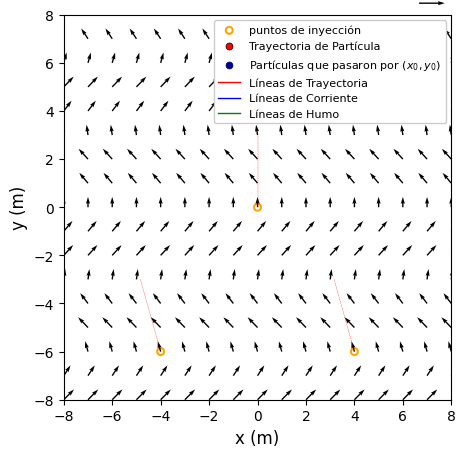

In [40]:
#Datos de Entrada
U = 1
V = 1
omega = 1

dt      = 0.05 #paso de tiempo (sec)
t_total = 3.0  #tiempo total de la animación (sec)

#Puntos (x0,y0) del origen de la inyección y del origen de la linea de trayectoria
x0 = [0, -4, 4]
y0 = [0, -6, -6]

#tamaño de espaciamiento en el espacio
dx = 0.1
dy = 0.1

#rango de valores 2D
xmin = -8
xmax = 8
ymin = -8
ymax = 8

#-----------------------------------------
#-----------------------------------------
nt = int(t_total/dt)
XT = []
YT = []
XT1 = []
YT1 = []
XT2 = []
YT2 = []
XH = []
YH = []

x = np.arange(xmin,xmax+dx,dx)
y = np.arange(ymin,ymax+dy,dy)

#Creamos el grafico
alto  = 5
ancho = 5

fig1, ax = plt.subplots(figsize=(ancho,alto))

#Definir cosas que no se mueven
ax.set_xlabel('x (m)',fontsize=12)
ax.set_ylabel('y (m)',fontsize=12)
ax.set_xlim(xmin,xmax)
ax.set_ylim(ymin,ymax)

#Lineas de Trayectoria (predibujadas)
tt = np.arange(0,t_total+dt,dt)
t0 = 0
for i in range(len(x0)):
  xxt = x0[i] + U*np.sin(omega*(t0- (y0[i]/V)))*(tt-t0)
  yyt = y0[i] + V*(tt-t0)
  ax.plot(xxt,yyt,linewidth=0.25,linestyle='--', color='r',zorder=2)
  if i == 0:
    ax.scatter(x0[i],y0[i], facecolors='none', edgecolors='orange', s=25, linewidths=1.5,label='puntos de inyección')
  else:
    ax.scatter(x0[i],y0[i], facecolors='none', edgecolors='orange', s=25, linewidths=1.5)

X, Y = np.meshgrid(x,y)

u = U*np.sin(omega*(0-Y/V))
v = V*np.ones(np.shape(u))

nq = 10

#mapa de colores
#quad = ax.pcolormesh(X,Y,np.zeros(np.shape(X)),shading='gouraud',cmap=plt.cm.jet, vmin=0, vmax = 5)
#mapa de flechas
Q = ax.quiver(X[::nq,::nq], Y[::nq,::nq], u[::nq,::nq], v[::nq,::nq], pivot='tail', color='k')
#escala de flechas
plt.quiverkey(Q,0.95,1.03,2.5,'2.5 = m/s')#, labelpos="E")

#eje de lineas de Trayectoria
line, = ax.plot([],[],linewidth=1.0, color='r',zorder=2,label='Líneas de Trayectoria')
lineT1, = ax.plot([],[],linewidth=1.0, color='r',zorder=2)
lineT2, = ax.plot([],[],linewidth=1.0, color='r',zorder=2)
#Scatter para Posición de Trayectoria de una Partícula de Fluido
lineb = ax.scatter([], [], s=25, c='r', edgecolors='k', linewidths=0.5,zorder=50,label = 'Trayectoria de Partícula')
linebT1 = ax.scatter([], [], s=25, c='r', edgecolors='k', linewidths=0.5,zorder=50)
linebT2 = ax.scatter([], [], s=25, c='r', edgecolors='k', linewidths=0.5,zorder=50)
#eje de lineas de Corrientes
line2, = ax.plot([],[],linewidth=1.0, color='b',zorder=2,label='Líneas de Corriente')
line2T1, = ax.plot([],[],linewidth=1.0, color='b',zorder=2)
line2T2, = ax.plot([],[],linewidth=1.0, color='b',zorder=2)
#eje de lineas de Humo
line3, = ax.plot([],[],linewidth=1.0, color='g',zorder=2,label='Líneas de Humo')
line3T1, = ax.plot([],[],linewidth=1.0, color='g',zorder=2)
line3T2, = ax.plot([],[],linewidth=1.0, color='g',zorder=2)
#Scatter para Posición de varias Partícula de Fluido que pasaron por el punto (xs,ys)
linec = ax.scatter([], [], s=25, c='darkblue', linewidths=0.5,zorder=10,label = 'Partículas que pasaron por $(x_{0},y_{0})$')
linecT1 = ax.scatter([], [], s=25, c='darkblue', linewidths=0.5,zorder=10)
linecT2 = ax.scatter([], [], s=25, c='darkblue', linewidths=0.5,zorder=10)

#ax.legend(loc='upper right',framealpha=1.0,fontsize=8)
handles, labels = plt.gca().get_legend_handles_labels()
order = [0,2,5,1,3,4]
ax.legend([handles[idx] for idx in order],[labels[idx] for idx in order],loc='upper right',framealpha=1.0,fontsize=8)

#paleta para el mapa de colores
#cbar = fig1.colorbar(quad)
#cbar.ax.set_ylabel('Velocidad (m/s)',fontsize=15)

#titulo (vacío, pero será dinámico)
time_text = ax.set_title('',fontsize=12)

In [41]:
XT = []
YT = []
XT1 = []
YT1 = []
XT2 = []
YT2 = []
XH = []
YH = []

def pathlines(x0,y0,t):
  xt = x0 + U*np.sin(omega*(t0- (y0/V)))*(t-t0)
  yt = y0 + V*(t-t0)
  return xt, yt

def streamlines(y,xlc,ylc,t):
  C1 = xlc - (U/omega)*np.cos(omega*(t-(ylc/V)))
  #y = V*(t - np.acos((omega/U)*(x-C1))/omega) #arccos
  x = C1 +  (U/omega)*np.cos(omega*(t-(y/V)))
  return x,y

def streaklines(xs,ys,dt,t):
  tau = np.arange(0,t+dt,dt)
  xh = xs + U*np.sin(omega*(tau - (ys/V)))*(t-tau)
  yh = ys + V*(t-tau)
  return xh, yh


def animate_0(t):
  t = t*dt
  #Campo de velocidad
  u = U*np.sin(omega*(t-Y/V))
  v = V*np.ones(np.shape(u))
  #Magnitud del vector velocidad
  Vel = np.sqrt(u**2 + v**2)
  #Lineas de Trayectoria
  xt, yt = pathlines(x0[0],y0[0],t)
  #print(xt)
  #print(yt)
  XT.append(xt)
  YT.append(yt)

  xt1, yt1 = pathlines(x0[1],y0[1],t)
  XT1.append(xt1)
  YT1.append(yt1)

  xt2, yt2 = pathlines(x0[2],y0[2],t)
  XT2.append(xt2)
  YT2.append(yt2)

  #Lineas de corriente
  xc, yc = streamlines(y,xt,yt,t)
  xc1, yc1 = streamlines(y,xt1,yt1,t)
  xc2, yc2 = streamlines(y,xt2,yt2,t)
  #lineas de Humo
  xh,yh = streaklines(x0[0],y0[0],dt,t)
  xh1,yh1 = streaklines(x0[1],y0[1],dt,t)
  xh2,yh2 = streaklines(x0[2],y0[2],dt,t)

  if t == 0:
    time_text.set_text('Tiempo = %0.1f (s)' % (t,))
    #XH.append(xh[-1])
    #YH.append(yh[-1])
  elif  t >0 and int(t/dt) % 2 == 0:
    time_text.set_text('Tiempo = %0.1f (s)' % (t,))
    #XH.append(xh[-1])
    #YH.append(yh[-1])

  #time_text.set_text('Tiempo = %0.2f (s)' % (t,))
  #quad.set_array(V.ravel())
  Q.set_UVC(u[::nq,::nq],v[::nq,::nq])
  line.set_data(XT,YT)
  lineT1.set_data(XT1,YT1)
  lineT2.set_data(XT2,YT2)
  lineb.set_offsets([xt,yt])
  linebT1.set_offsets([xt1,yt1])
  linebT2.set_offsets([xt2,yt2])
  line2.set_data(xc,yc)
  line2T1.set_data(xc1,yc1)
  line2T2.set_data(xc2,yc2)
  line3.set_data(xh,yh)
  line3T1.set_data(xh1,yh1)
  line3T2.set_data(xh2,yh2)
  #vector = np.c_[np.array([XH, YH])]
  #linec.set_offsets(vector)
  linec.set_offsets(np.c_[xh[::10],yh[::10]])
  linecT1.set_offsets(np.c_[xh1[::10],yh1[::10]])
  linecT2.set_offsets(np.c_[xh2[::10],yh2[::10]])
  return t,#Q#, time_text

anim = animation.FuncAnimation(fig1, animate_0, frames=nt+1, interval=100, blit=False)

#anim.save(filename='example.mp4', writer='ffmpeg',bitrate=20)

HTML(anim.to_jshtml())